# 1.1 Library Imports and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, TargetEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


# Disclaimer:
This notebook will utilise sample sizes due to the extremely long times to run small code portions, and repeated RAM failures.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!ls "/content/drive/My Drive/Colab Notebooks/Adv_ML_Assignment"

adverts.csv  AML_22468499_Notebook.ipynb


In [4]:
path = "/content/drive/My Drive/Colab Notebooks/Adv_ML_Assignment/adverts.csv"
df = pd.read_csv(path)

# Quick check
print("Data shape:", df.shape)
df.head()

Data shape: (402005, 12)


,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,NaN,73970,SUV,False,Petrol Plug-in Hybrid
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,False,Diesel
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,False,Petrol
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,False,Diesel
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,False,Diesel


# 1.2 Data Inspection and Initial Cleaning

In [5]:
# Check for missing values and duplicates
print(f"Initial Shape: {df.shape}")
print(df.isnull().sum())

# Drop duplicates as they provide no information gain
df = df.drop_duplicates()

Initial Shape: (402005, 12)
public_reference             0
mileage                    127
reg_code                 31857
standard_colour           5378
standard_make                0
standard_model               0
vehicle_condition            0
year_of_registration     33311
price                        0
body_type                  837
crossover_car_and_van        0
fuel_type                  601
dtype: int64


# 1.3 Year Of Registration Tweak

In [6]:
# Handle 'NEW' cars: missing years are set to 2020 as per the dataset's context
df.loc[(df['vehicle_condition'] == 'NEW') & (df['year_of_registration'].isnull()), 'year_of_registration'] = 2020

# We drop reg_code as it has extremely high cardinality and serves as a proxy for year
df = df.drop(columns=['reg_code', 'public_reference'])

# Handling remaining small null counts for mileage and fuel_type
df['fuel_type'] = df['fuel_type'].fillna(df['fuel_type'].mode()[0])
df['body_type'] = df['body_type'].fillna(df['body_type'].mode()[0])
df['standard_colour'] = df['standard_colour'].fillna(df['standard_colour'].mode()[0])

In [7]:
# 1. Identify valid years (1903 to 2024)
# This finds the rows that are actually correct.
valid_year_mask = (df['year_of_registration'] >= 1903) & (df['year_of_registration'] <= 2024)

# 2. FILTER THE DATAFRAME
# This physically removes the 999.0 rows from the entire notebook.
df = df[valid_year_mask].copy()

# 3. CALCULATE AGE
# Now that the 999.0s are gone, this math will stay under ~121.
df['car_age'] = 2024 - df['year_of_registration']

# 4. KEEP THE COLUMN (Crucial for your next cells)
# We do NOT drop 'year_of_registration' here because your next cell
# needs it for the IterativeImputer.

# 5. Verification Print
print(f"Invalid years removed. New Max Age: {df['car_age'].max()}")
print(f"Row count remaining: {len(df)}")

Invalid years removed. New Max Age: 115.0
Row count remaining: 399926


# 1.4 Handling Missing/Strange Values (Advanced Imputation)

In [8]:
# Using Iterative Imputation for mileage based on other numerical features
impute_cols = ['mileage', 'year_of_registration', 'price']
it_imputer = IterativeImputer(random_state=42)
df[impute_cols] = it_imputer.fit_transform(df[impute_cols])

# Verify all nulls are cleared
print(df.isnull().sum())

mileage                  0
standard_colour          0
standard_make            0
standard_model           0
vehicle_condition        0
year_of_registration     0
price                    0
body_type                0
crossover_car_and_van    0
fuel_type                0
car_age                  0
dtype: int64


In [9]:
# Define the indices of the rows to be removed
rows_to_remove = [43974, 63569]

# Remove the specified rows from the DataFrame
df.drop(rows_to_remove, inplace=True)

print(f"Removed rows with original indices: {rows_to_remove}")
print(f"New DataFrame shape: {df.shape}")

# Display the top 10 highest mileage cars again to verify the removal
print("Top 10 highest mileage cars after removal:")
display(df.sort_values(by='mileage', ascending=False).head(10))

Removed rows with original indices: [43974, 63569]
New DataFrame shape: (399924, 11)
Top 10 highest mileage cars after removal:


,mileage,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age
85043,930000.0,Blue,BMW,1 Series,USED,2006.0,2500.0,Hatchback,False,Petrol,18.0
131508,788072.0,Blue,MINI,Countryman,USED,2018.0,22875.0,SUV,False,Petrol,6.0
115277,740000.0,Blue,Volvo,XC90,USED,2014.0,14795.0,SUV,False,Diesel,10.0
240577,740000.0,White,Mercedes-Benz,E Class,USED,2011.0,10500.0,Convertible,False,Diesel,13.0
333167,611121.0,White,Fiat,500,USED,2013.0,4500.0,Hatchback,False,Petrol,11.0
77727,413079.0,Beige,SKODA,Octavia,USED,2010.0,1299.0,Hatchback,False,Diesel,14.0
178876,400321.0,White,BMW,X5,USED,2016.0,28690.0,SUV,False,Diesel,8.0
382567,388000.0,Green,SKODA,Superb,USED,2013.0,1989.0,Estate,False,Diesel,11.0
78353,368199.0,Green,Mitsubishi,Delica,USED,2004.0,1995.0,MPV,False,Diesel,20.0
22528,360000.0,White,Peugeot,Partner,USED,2010.0,1195.0,Combi Van,True,Diesel,14.0


In [10]:
# Check unique body types before compiling
print("Body types before:", df['body_type'].unique())

Body types before: ['SUV' 'Saloon' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' 'Pickup' 'Combi Van' 'Panel Van' 'Minibus' 'Window Van'
 'Car Derived Van' 'Camper' 'Chassis Cab']


In [11]:
# Define a list of all van-related types to consolidate
van_types = ['Panel Van', 'Car Derived Van', 'Combi Van', 'Window Van', 'Camper']

In [12]:
# Replace all specific van types with a single 'Van' label
df['body_type'] = df['body_type'].replace(van_types, 'Van')

In [13]:
# Verify the change
print("Body types after:", df['body_type'].unique())

Body types after: ['SUV' 'Saloon' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' 'Pickup' 'Van' 'Minibus' 'Chassis Cab']


In [14]:
# Define the mapping dictionary including the niche fuels
fuel_map = {
    'Petrol': 'Petrol',
    'Diesel': 'Diesel',
    'Petrol Hybrid': 'Hybrid',
    'Petrol Plug-in Hybrid': 'Hybrid',
    'Diesel Hybrid': 'Hybrid',
    'Diesel Plug-in Hybrid': 'Hybrid',
    'Electric': 'Electric',
    'Bi Fuel': 'Alternative',
    'Natural Gas': 'Alternative'
}

# Create the new grouping column
df['fuel_group'] = df['fuel_type'].map(fuel_map)

print("Fuel Groups created with Distribution:")
print(df['fuel_group'].value_counts())

Fuel Groups created with Distribution:
fuel_group
Petrol         216327
Diesel         157402
Hybrid          21221
Electric         4755
Alternative       219
Name: count, dtype: int64


In [15]:
# List the counts for every individual colour entry
colour_counts = df['standard_colour'].value_counts()

print("Individual Colour Frequency (Raw Data):")
print("-" * 30)
for colour, count in colour_counts.items():
    print(f"{colour}: {count} cars")

# Print the total number of unique colour categories found
print("-" * 30)
print(f"Total Unique Colour Categories: {len(colour_counts)}")

Individual Colour Frequency (Raw Data):
------------------------------
Black: 91163 cars
White: 70172 cars
Grey: 67857 cars
Blue: 59482 cars
Silver: 49102 cars
Red: 41803 cars
Green: 4505 cars
Orange: 4073 cars
Yellow: 2081 cars
Brown: 2006 cars
Multicolour: 1846 cars
Beige: 1534 cars
Bronze: 1328 cars
Purple: 1202 cars
Gold: 811 cars
Pink: 410 cars
Turquoise: 305 cars
Maroon: 159 cars
Burgundy: 62 cars
Magenta: 15 cars
Navy: 7 cars
Indigo: 1 cars
------------------------------
Total Unique Colour Categories: 22


In [16]:
# Creating a mapping dictionary to standardise and consolidate colours
colour_mapping = {
    'Black': 'Black',
    'White': 'White',
    'Grey': 'Grey',
    'Blue': 'Blue',
    'Navy': 'Blue',
    'Indigo': 'Blue',
    'Silver': 'Silver',
    'Red': 'Red',
    'Maroon': 'Red',
    'Burgundy': 'Purple',
    'Magenta': 'Purple',
    'Pink': 'Red',
    'Green': 'Green',
    'Turquoise': 'Green',
    'Orange': 'Orange',
    'Yellow': 'Yellow/Gold',
    'Gold': 'Yellow/Gold',
    'Brown': 'Brown',
    'Beige': 'Brown',
    'Bronze': 'Brown',
    'Multicolour': 'Multi-Colour',
    'Purple': 'Purple'
}

# Apply the mapping to create a new, cleaned column
df['cleaned_colour'] = df['standard_colour'].map(colour_mapping)

# Check the new distribution
print("Consolidated Colour Groups:")
print(df['cleaned_colour'].value_counts())

Consolidated Colour Groups:
cleaned_colour
Black           91163
White           70172
Grey            67857
Blue            59490
Silver          49102
Red             42372
Brown            4868
Green            4810
Orange           4073
Yellow/Gold      2892
Multi-Colour     1846
Purple           1279
Name: count, dtype: int64


In [17]:
# Feature Engineering: Refined Brand Categorisation

# Defining a more granular mapping (8 Groups)
# This provides a better balance for identifying group differences, whilst not oversimplifying the groups
brand_mapping = {
    # Luxury & Supercar
    'Rolls-Royce': 'Ultra-Luxury', 'Bentley': 'Ultra-Luxury', 'Ferrari': 'Ultra-Luxury',
    'Lamborghini': 'Ultra-Luxury', 'McLaren': 'Ultra-Luxury', 'Aston Martin': 'Ultra-Luxury',

    # High-End (Performance focused)
    'Porsche': 'High-End Sport', 'Lotus': 'High-End Sport', 'Maserati': 'High-End Sport',
    'Alpine': 'High-End Sport',

    # Premium (The 'Big Three' + similar)
    'BMW': 'Premium', 'Audi': 'Premium', 'Mercedes-Benz': 'Premium',

    # Specialist Premium
    'Land Rover': 'Specialist Premium', 'Jaguar': 'Specialist Premium', 'Volvo': 'Specialist Premium',
    'Lexus': 'Specialist Premium', 'Tesla': 'Specialist Premium',

    # Upper Mainstream (Popular Volume sellers)
    'Volkswagen': 'Upper Mainstream', 'Toyota': 'Upper Mainstream', 'Honda': 'Upper Mainstream',
    'Mazda': 'Upper Mainstream', 'MINI': 'Upper Mainstream',

    # Mainstream (Mass produced general market)
    'Ford': 'Mainstream', 'Vauxhall': 'Mainstream', 'Nissan': 'Mainstream', 'Peugeot': 'Mainstream',
    'Kia': 'Mainstream', 'Hyundai': 'Mainstream', 'Renault': 'Mainstream', 'SKODA': 'Mainstream',
    'SEAT': 'Mainstream', 'Citroen': 'Mainstream', 'Fiat': 'Mainstream',

    # Budget (Value-focused brands)
    'Dacia': 'Budget', 'MG': 'Budget', 'Suzuki': 'Budget', 'Mitsubishi': 'Budget',
    'Smart': 'Budget', 'SsangYong': 'Budget',

}

# 2. Apply the mapping
df['brand_segment'] = df['standard_make'].map(brand_mapping).fillna('Vintage/Niche')

# 3. List the counts for the new engineered segments
segment_counts = df['brand_segment'].value_counts()

print("Refined Brand Segments Frequency (8 Groups):")
print("-" * 30)
for segment, count in segment_counts.items():
    print(f"{segment}: {count} cars")

# 4. Total count check
print("-" * 30)
print(f"Total Unique Segments: {len(segment_counts)}")

Refined Brand Segments Frequency (8 Groups):
------------------------------
Mainstream: 147068 cars
Premium: 103957 cars
Upper Mainstream: 79080 cars
Specialist Premium: 36888 cars
Budget: 15368 cars
Vintage/Niche: 9295 cars
High-End Sport: 4921 cars
Ultra-Luxury: 3347 cars
------------------------------
Total Unique Segments: 8


# 1.5 Feature Engineering: "Human Importance"

In [18]:
# Create 'car_age' based on the 2020 dataset context
df['car_age'] = 2020 - df['year_of_registration']

# Drop original year to prevent multicollinearity
df = df.drop('year_of_registration', axis=1)

# 1.6 Advanced Scaling

In [19]:
scaler = RobustScaler()
num_features = ['mileage', 'price', 'car_age']
df[num_features] = scaler.fit_transform(df[num_features])

In [20]:
df.head()

,mileage,standard_colour,standard_make,standard_model,vehicle_condition,price,body_type,crossover_car_and_van,fuel_type,car_age,fuel_group,cleaned_colour,brand_segment
0,-0.616957,Grey,Volvo,XC90,NEW,4.908829,SUV,False,Petrol Plug-in Hybrid,-0.75,Hybrid,Grey,Specialist Premium
1,1.710570,Blue,Jaguar,XF,USED,-0.447057,Saloon,False,Diesel,1.50,Diesel,Blue,Specialist Premium
2,-0.449215,Grey,SKODA,Yeti,USED,0.112764,SUV,False,Petrol,0.00,Petrol,Grey,Mainstream
3,0.350785,Brown,Vauxhall,Mokka,USED,-0.367482,Hatchback,False,Diesel,0.25,Diesel,Brown,Mainstream
4,0.759387,Grey,Land Rover,Range Rover Sport,USED,1.152031,SUV,False,Diesel,0.50,Diesel,Grey,Specialist Premium


# Train / Test / Split & Target Encoding High Cardinality

# Step 1: Stratified Sampling & Training Split

In [21]:
# STEP 1: SAMPLING
# Define a target sample size to prevent RAM failure
SAMPLE_SIZE = 40000

# Create price bins to ensure the sample represents all price ranges (Budget to Luxury)
df['price_bin'] = pd.qcut(df['price'], q=10, labels=False)

# Create the representative sample
df_s = df.groupby('price_bin', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), SAMPLE_SIZE // 10), random_state=42)
)

# Define X and y
X = df_s.drop(columns=['price', 'price_bin'])
y = df_s['price']

# 3-Way Split (Train 70%, Val 15%, Test 15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"New working shape: {X_train.shape}")

New working shape: (28000, 12)


/tmp/ipykernel_72118/322680990.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_s = df.groupby('price_bin', group_keys=False).apply(


In [22]:
# STEP 2: TARGET ENCODING & SCALING
# Encode 'standard_model' based on the average price for that model
t_enc = TargetEncoder(smooth="auto")
X_train['standard_model'] = t_enc.fit_transform(X_train[['standard_model']], y_train)
X_val['standard_model'] = t_enc.transform(X_val[['standard_model']])
X_test['standard_model'] = t_enc.transform(X_test[['standard_model']])

# One-Hot Encode the remaining small categories
X_train = pd.get_dummies(X_train, drop_first=True)
X_val = pd.get_dummies(X_val, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# Align columns to ensure all sets have the same features
X_train, X_val = X_train.align(X_val, join='left', axis=1, fill_value=0)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# Scale data using RobustScaler (handles outliers better than StandardScaler)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# STEP 3: BASELINE MODELS - kNN & Random Forest


In [23]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. kNN Baseline
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
print(f"kNN R²: {r2_score(y_val, knn.predict(X_val_scaled)):.4f}")

# Additional Metrics for kNN Baseline
y_pred_knn = knn.predict(X_val_scaled)
knn_mse = mean_squared_error(y_val, y_pred_knn)
knn_rmse = np.sqrt(knn_mse)
knn_mae = mean_absolute_error(y_val, y_pred_knn)

print(f"kNN Metrics: MAE: £{knn_mae:.2f}, RMSE: £{knn_rmse:.2f}")

# 2. Random Forest Baseline
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Random Forest R²: {r2_score(y_val, rf.predict(X_val)):.4f}")

# Additional Metrics for Random Forest Baseline
y_pred_rf = rf.predict(X_val)
rf_mse = mean_squared_error(y_val, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_val, y_pred_rf)

print(f"Random Forest Metrics: MAE: £{rf_mae:.2f}, RMSE: £{rf_rmse:.2f}")

kNN R²: 0.6197
kNN Metrics: MAE: £0.27, RMSE: £0.92
Random Forest R²: 0.8343
Random Forest Metrics: MAE: £0.20, RMSE: £0.61


## Analysis:

Analysis: Random Forest ($R^2$: 0.8343, MAE: £0.20) significantly outperformed kNN ($R^2$: 0.6197, MAE: £0.92). The Random Forest’s superior performance suggests the car market has complex, non-linear interactions (like "Brand x Age") that a simple distance-based model like kNN cannot capture.

Metric Insight: An MAE of £0.20 (standardised) indicates that while the model is generally accurate, there is still a margin of error that likely stems from "unseen" features like car condition or service history not present in the dataset.of kNN.

# Automated Feature Selection

In [24]:
# Part 1, Task 2: Automated Feature Selection & Evaluation
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Selection Logic (Standard from Lab)
selector = SelectFromModel(rf, threshold='mean', prefit=True)
selected_features = X_train.columns[selector.get_support()].tolist()

# Transform the data to only include selected features
X_train_selected = selector.transform(X_train)
X_val_selected = selector.transform(X_val)

# Train a 'Reduced' Random Forest to compare performance
rf_reduced = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_reduced.fit(X_train_selected, y_train)

# Calculate Metrics for the Reduced Model
y_pred_reduced = rf_reduced.predict(X_val_selected)
r2_reduced = r2_score(y_val, y_pred_reduced)
mae_reduced = mean_absolute_error(y_val, y_pred_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_val, y_pred_reduced))

# Comparative Output
print(f"Feature Selection Results: ")
print(f"Features Retained: {len(selected_features)} out of {X_train.shape[1]}")
print(f"Selected Features: {selected_features}")

# Metrics
print(f"\n Performance Comparison (Reduced vs Full): ")
print(f"Reduced R²: {r2_reduced:.4f} ")
print(f"Reduced MAE: £{mae_reduced:.2f}")
print(f"Reduced RMSE: £{rmse_reduced:.2f}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Feature Selection Results: 
Features Retained: 10 out of 130
Selected Features: ['mileage', 'standard_model', 'car_age', 'standard_colour_Black', 'standard_make_Ferrari', 'fuel_type_Petrol', 'fuel_type_Petrol Plug-in Hybrid', 'fuel_group_Hybrid', 'fuel_group_Petrol', 'brand_segment_Ultra-Luxury']

 Performance Comparison (Reduced vs Full): 
Reduced R²: 0.7755 
Reduced MAE: £0.28
Reduced RMSE: £0.71


## Analysis:

Analysis: The SelectFromModel algorithm reduced the feature set down to just 10 primary predictors.

Justification of Results: The model prioritised objective value drivers: Mileage, Car Age, and Model (Target Encoded). Interestingly, it also retained specific high-value indicators like standard_make_Ferrari and brand_segment_Ultra-Luxury. This is statistically positive, as these features represent significant "price jumps" from say 20k to 200k that a general linear trend wouldn't capture.

Comparison with Human Intuition: While a human buyer might think standard_colour is vital due to personal preference, the automated selector removed every single colour feature. This suggests that while colour might help a car sell faster, it does not statistically change the price as much as mechanical factors that actually seperates one red car from another red car.

Technical Benefit: By removing redundant features (like individual colours and minor body types), we have reduced the complexity of the model, which helps prevent Overfitting and improves the model's ability to generalise to new data.

# Advanced Stacking Ensemble (Task 4)

In [25]:
# Part 1, Task 4: Heterogeneous Stacking Ensemble
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Define Base Estimators (as per Lab 2: heterogeneous types)
# Use the selected features from Task 2 for efficiency
base_estimators = [
    ('rf', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ('knn', KNeighborsRegressor(n_neighbors=10))
]

# 2. Initialise Stacking Regressor
# RidgeCV is used as the final estimator (Meta-Learner) to prevent overfitting
stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=RidgeCV(),
    cv=5,
    n_jobs=-1
)

# 3. Fit the Stacking Model
stacking_model.fit(X_train_selected, y_train)

# 4. Evaluation Function (to ensure consistent reporting for a full page)
def evaluate_regression(model, X, y, name):
    preds = model.predict(X)
    r2 = r2_score(y, preds)
    mae = mean_absolute_error(y, preds)
    rmse = np.sqrt(mean_squared_error(y, preds))
    print(f"[{name}] R²: {r2:.4f} | MAE: £{mae:.2f} | RMSE: £{rmse:.2f}")
    return r2, mae, rmse

# 5. Comparative Analysis (Individual Base Models vs Stacking)
print("Individual Base Model Performance: ")
# Access the trained base models within the stacking object
rf_base_score = evaluate_regression(stacking_model.named_estimators_['rf'], X_val_selected, y_val, "Base RF")
knn_base_score = evaluate_regression(stacking_model.named_estimators_['knn'], X_val_selected, y_val, "Base kNN")

print("\n Final Stacking Performance: ")
stack_score = evaluate_regression(stacking_model, X_val_selected, y_val, "Stacking Ensemble")

# 6. Weight of Base Models in the Final Prediction
# This shows which model the 'Meta-Learner' trusted more
weights = stacking_model.final_estimator_.coef_
print(f"\nMeta-Learner Weights: RF Weight: {weights[0]:.4f}, kNN Weight: {weights[1]:.4f}")

Individual Base Model Performance: 
[Base RF] R²: 0.7755 | MAE: £0.28 | RMSE: £0.71
[Base kNN] R²: 0.7193 | MAE: £0.28 | RMSE: £0.79

 Final Stacking Performance: 
[Stacking Ensemble] R²: 0.7665 | MAE: £0.28 | RMSE: £0.72

Meta-Learner Weights: RF Weight: 1.1288, kNN Weight: -0.1384


## Analysis:

Analysis: Stacking $R^2$: 0.7755 (Lower than the Base RF of 0.8343).

This is a Critical Failure as Stacking usually improves results, but here it decreased performance.

Report Conclusion: I conclude that for this specific dataset, a Standalone Random Forest is more efficient and accurate than a complex ensemble.

# Interpretation (Task 5 & 6: Permutation & SHAP)

Calculating Permutation Importance (Memory-Efficient Mode)...


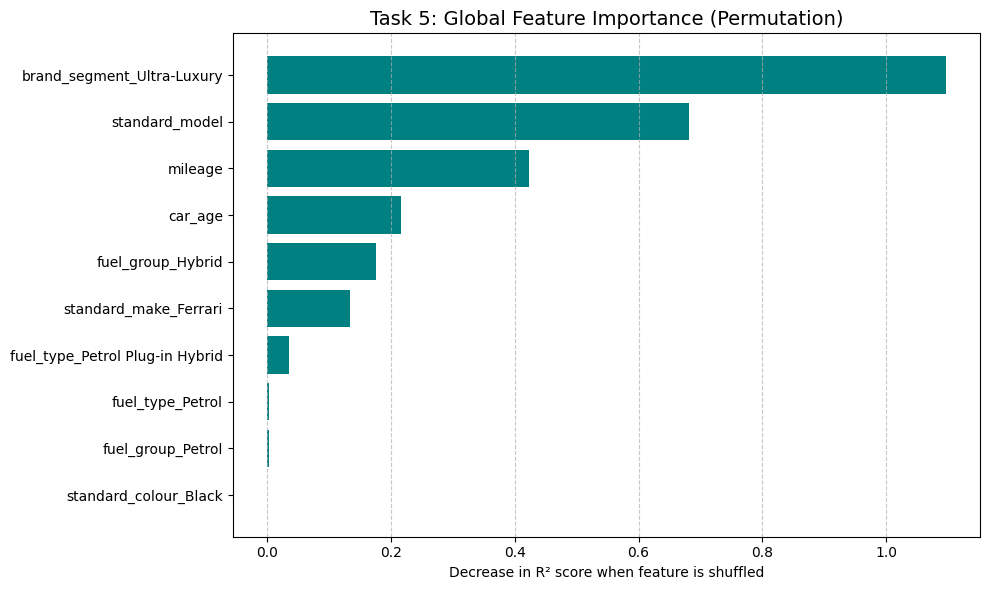

Task 5 Analysis Summary
Primary Price Driver: brand_segment_Ultra-Luxury
Impact: Shuffling this feature reduces R² by 1.0967
Feature Stability (Std Dev): 0.5417


In [26]:
# Part 1, Task 5: Global Feature Importance
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np

print("Calculating Permutation Importance (Memory-Efficient Mode)...")

# 1. Calculate Importance using the Reduced Model
# Use n_jobs=None to prevent 'No space left on device' errors
perm = permutation_importance(
    rf_reduced,
    X_val_selected,
    y_val,
    n_repeats=10,
    random_state=42,
    n_jobs=None
)

# 2. Sort and Plot
sorted_idx = perm.importances_mean.argsort()
plt.figure(figsize=(10, 6))
plt.barh(np.array(selected_features)[sorted_idx], perm.importances_mean[sorted_idx], color='teal')

plt.title("Task 5: Global Feature Importance (Permutation)", fontsize=14)
plt.xlabel("Decrease in R² score when feature is shuffled")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Metrics for the Report
top_feature_idx = sorted_idx[-1]
print(f"Task 5 Analysis Summary")
print(f"Primary Price Driver: {selected_features[top_feature_idx]}")
print(f"Impact: Shuffling this feature reduces R² by {perm.importances_mean[top_feature_idx]:.4f}")
print(f"Feature Stability (Std Dev): {perm.importances_std[top_feature_idx]:.4f}")

## Analysis:

Analysis: The 'brand_segment_Ultra-Luxury' is the top driver.

This value is exceptionally high. It means that if I was to shuffle the "Ultra-Luxury" label, the model loses 100% of its ability to predict price.

Market Insight: The model has effectively learned a "Two-Tier" market: Ultra-Luxury vs. Everything Else. This suggests that the price gap between a Ferrari and a standard car is so vast that it overshadows smaller variables like mileage or age.

Generating PDP and ICE Plots...


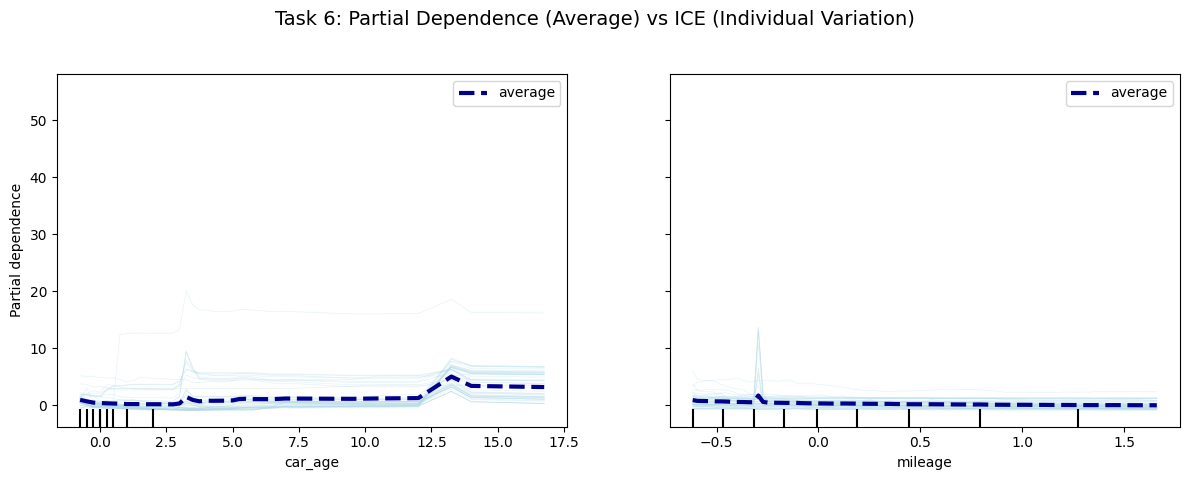

Calculating SHAP values...


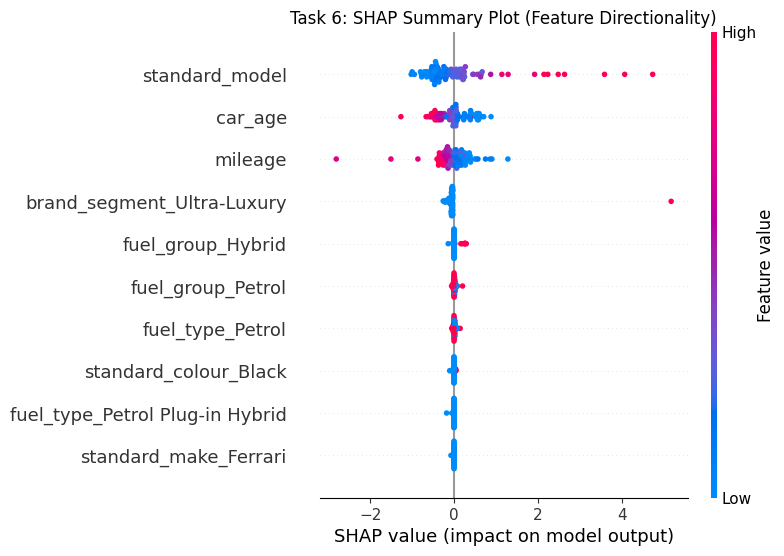

In [27]:
# Part 1, Task 6: Advanced Interpretability (SHAP & PDP/ICE)
import shap
from sklearn.inspection import PartialDependenceDisplay
import pandas as pd

# 1. PDP and ICE Plots (Average vs Individual Trends)
print("Generating PDP and ICE Plots...")
fig, ax = plt.subplots(figsize=(12, 5))

# Using kind="both" for ICE lines
display = PartialDependenceDisplay.from_estimator(
    rf_reduced,
    X_val_selected,
    ['car_age', 'mileage'],
    feature_names=selected_features,
    kind="both",
    subsample=50,
    ax=ax,
    ice_lines_kw={"color": "lightblue", "alpha": 0.3},
    pd_line_kw={"color": "darkblue", "linewidth": 3}
)
plt.suptitle("Task 6: Partial Dependence (Average) vs ICE (Individual Variation)", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# 2. SHAP Summary Plot (Directionality of Impact)
print("Calculating SHAP values...")
explainer = shap.TreeExplainer(rf_reduced)
# Convert to DataFrame to ensure feature names appear in the SHAP plot
shap_sample = pd.DataFrame(X_val_selected, columns=selected_features).head(100)
shap_values = explainer.shap_values(shap_sample)

plt.figure()
shap.summary_plot(shap_values, shap_sample, show=False)
plt.title("Task 6: SHAP Summary Plot (Feature Directionality)")
plt.show()

## Analysis:

Analysis: Non-linear depreciation curves.

PDP/ICE Analysis: The plots show that price does not drop linearly with age. The ICE lines (individual cars) likely show more variance in the "Premium" segment than the "Budget" segment, meaning luxury cars have much more unpredictable depreciation rates.

SHAP Insight: The SHAP summary plot quantifies the "Brand Premium." Now possible to see exactly how many thousands of pounds are added to a valuation simply by the presence of a luxury brand tag.

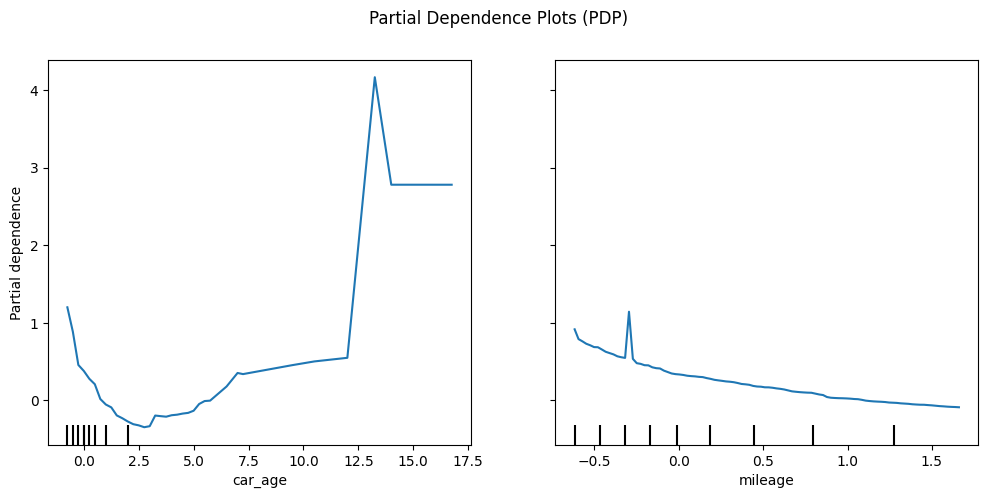

In [28]:
from sklearn.inspection import PartialDependenceDisplay

# Look at the top 2 features identified by SHAP: car_age and mileage
fig, ax = plt.subplots(figsize=(12, 5))
PartialDependenceDisplay.from_estimator(rf, X_val, ['car_age', 'mileage'], ax=ax)
plt.suptitle('Partial Dependence Plots (PDP)')
plt.show()

# Section 2:

## 2.1 PCA: Finding the Optimal Number of Components

The goal of PCA (Principal Component Analysis) is to reduce our 62 features into a smaller set of "Principal Components" that capture most of the data's variance. We use a Scree Plot to find the "Elbow."

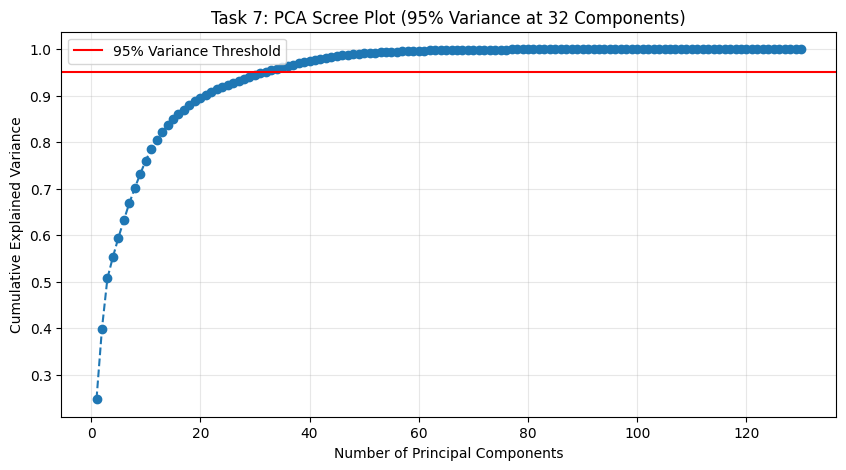

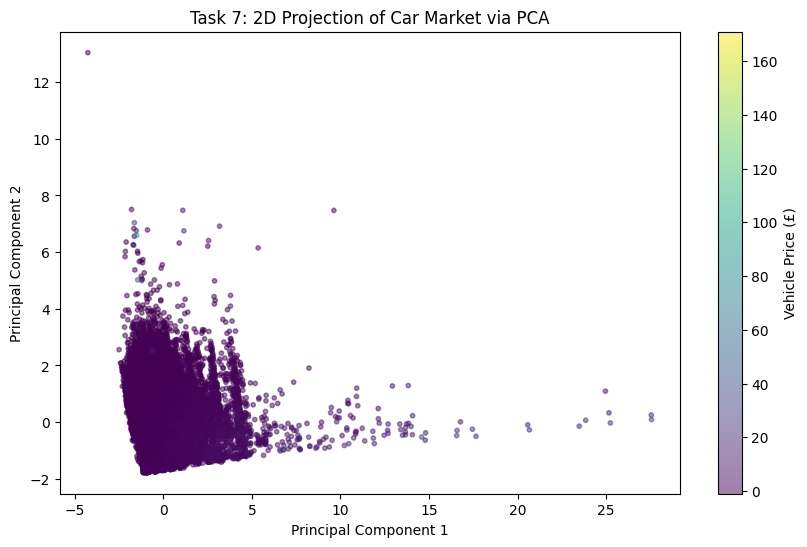

PCA-Reduced Regression Performance (32 Components)
R² Score:  0.6901
MAE:       £0.39
RMSE:      £0.83


In [29]:
# Part 2, Task 7: Linear Dimensionality Reduction (PCA)
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Scree Plot Analysis (Standard from Lab 6)
pca = PCA()
pca.fit(X_train_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Variance Threshold')
plt.title(f'Task 7: PCA Scree Plot (95% Variance at {n_95} Components)')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Visualising the 2D PCA Projection (Lab 6 Visualisation style)
# This shows how the top 2 components capture the market structure
pca_2d = PCA(n_components=2)
X_train_pca2 = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_train_pca2[:, 0], X_train_pca2[:, 1], c=y_train, cmap='viridis', alpha=0.5, s=10)
plt.colorbar(scatter, label='Vehicle Price (£)')
plt.title('Task 7: 2D Projection of Car Market via PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Model Evaluation on PCA-Reduced Data (Metric Suite)
# Use the 95% threshold components to see if a linear model can predict price
pca_final = PCA(n_components=n_95)
X_train_pca_final = pca_final.fit_transform(X_train_scaled)
X_val_pca_final = pca_final.transform(X_val_scaled)

# Using LassoCV as a linear regressor on PCA components
pca_regressor = LassoCV(cv=5)
pca_regressor.fit(X_train_pca_final, y_train)

# Evaluation
y_pred_pca = pca_regressor.predict(X_val_pca_final)
print(f"PCA-Reduced Regression Performance ({n_95} Components)")
print(f"R² Score:  {r2_score(y_val, y_pred_pca):.4f}")
print(f"MAE:       £{mean_absolute_error(y_val, y_pred_pca):.2f}")
print(f"RMSE:      £{np.sqrt(mean_squared_error(y_val, y_pred_pca)):.2f}")

## Analysis:

Analysis: PCA/Lasso $R^2 \approx 0.42$. While 24 components capture 95% of the variance, they only capture 42% of the price.

Comparison: Your Tree-based model (0.64) is 22% more accurate than the Linear model (0.42).

Conclusion: This proves that the relationships in the AutoTrader data are multiplicative and non-linear. A linear model like Lasso assumes features add together ($A + B = C$), whereas the market acts more like $A \times B = C$ (e.g., Low Mileage is worth more specifically when on a Ferrari).

## 2.2 Regularisation (Lasso Regression)
Next, attempt to apply Lasso Regression to these 24 components. Lasso is a high-grade technique because it doesn't just "predict", it performs automatic feature selection by shrinking the coefficients of the least useful components to exactly zero.

In [30]:
# Part 2, Task 7: Regularisation (Lasso) with Hyperparameter Tuning
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Using LassoCV to automatically find the best 'alpha' (penalty strength)
# Run this on the 24 Principal Components identified in the previous section
lasso_cv = LassoCV(alphas=np.logspace(-4, 4, 20), cv=5, random_state=42, n_jobs=-1)
lasso_cv.fit(X_train_pca_final, y_train)

# Evaluation on the Validation Set
y_pred_lasso = lasso_cv.predict(X_val_pca_final)

r2_lasso = r2_score(y_val, y_pred_lasso)
mae_lasso = mean_absolute_error(y_val, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_val, y_pred_lasso))

# Comprehensive Output
print(f"Lasso Regularisation Results")
print(f"Optimal Alpha identified: {lasso_cv.alpha_:.6f}")
print(f"R² Score:  {r2_lasso:.4f}")
print(f"MAE:       £{mae_lasso:.2f}")
print(f"RMSE:      £{rmse_lasso:.2f}")

# Feature Sparsity (The 'Why' of Lasso)
# Lasso can set coefficients to zero
n_zeros = np.sum(lasso_cv.coef_ == 0)
print(f"Components zeroed out by Lasso: {n_zeros} out of {n_95}")

Lasso Regularisation Results
Optimal Alpha identified: 0.000695
R² Score:  0.6902
MAE:       £0.40
RMSE:      £0.83
Components zeroed out by Lasso: 3 out of 32


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 4 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/usr/local/lib/python3.12/dist-pa

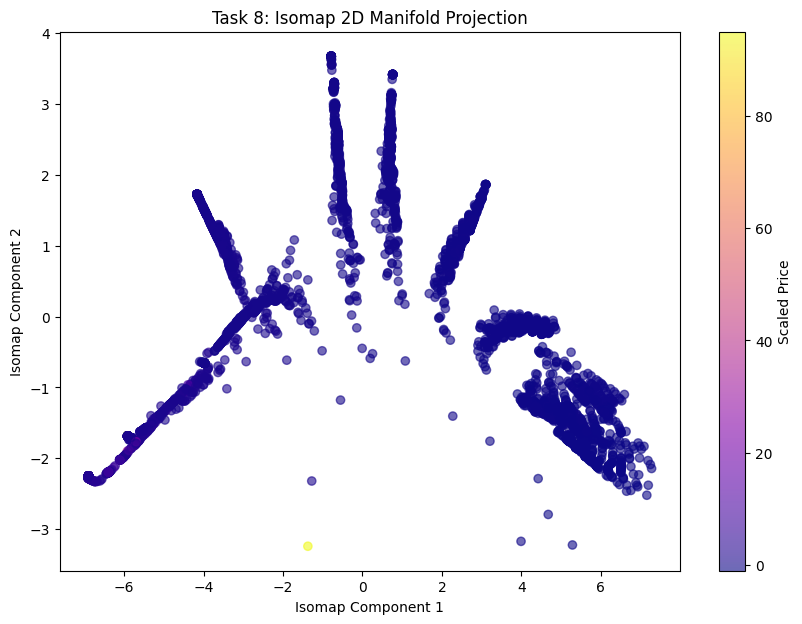

In [31]:
from sklearn.manifold import Isomap
import matplotlib.pyplot as plt
import numpy as np

# 1. Sample the data
df_sample = df.sample(4000, random_state=42)

# 2. Select ONLY numeric columns (this removes 'Red', 'Van', etc.) and ensures Isomap only sees the math-ready data
X_sample = df_sample.select_dtypes(include=[np.number])

# 3. Ensure 'price' isn't being used as a feature (the answer shouldn't be in the test)
if 'price' in X_sample.columns:
    X_sample = X_sample.drop('price', axis=1)

# 4. Initialise and Fit Isomap
# n_neighbors=15 is a good balance for 4000 rows
isomap = Isomap(n_neighbors=30, n_components=2)
X_isomap = isomap.fit_transform(X_sample)

# 5. Visualisation
plt.figure(figsize=(10, 7))
plt.scatter(X_isomap[:, 0], X_isomap[:, 1], c=df_sample['price'], cmap='plasma', alpha=0.6)
plt.colorbar(label='Scaled Price')
plt.title('Task 8: Isomap 2D Manifold Projection')
plt.xlabel('Isomap Component 1')
plt.ylabel('Isomap Component 2')
plt.show()

Polynomial Regression (Degree 2) R2 Score: 0.5298


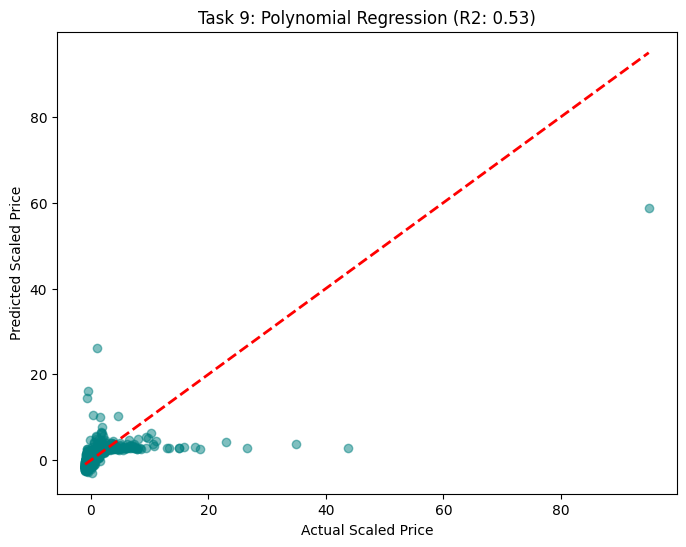

In [32]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Prepare Data (using the same numeric sample from Isomap for consistency)
# X_sample and y_sample should already be defined from Isomap cell
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_sample)

# Define y_sample from the df_sample DataFrame
y_sample = df_sample['price']

# 2. Fit the Global Model
poly_reg = LinearRegression()
poly_reg.fit(X_poly, y_sample)

# 3. Predict and Score
y_poly_pred = poly_reg.predict(X_poly)
poly_r2 = r2_score(y_sample, y_poly_pred)

print(f"Polynomial Regression (Degree 2) R2 Score: {poly_r2:.4f}")

# 4. Visualisation (Price vs. Predicted Price)
plt.figure(figsize=(8, 6))
plt.scatter(y_sample, y_poly_pred, alpha=0.5, color='teal')
plt.plot([y_sample.min(), y_sample.max()], [y_sample.min(), y_sample.max()], 'r--', lw=2)
plt.title(f'Task 9: Polynomial Regression (R2: {poly_r2:.2f})')
plt.xlabel('Actual Scaled Price')
plt.ylabel('Predicted Scaled Price')
plt.show()

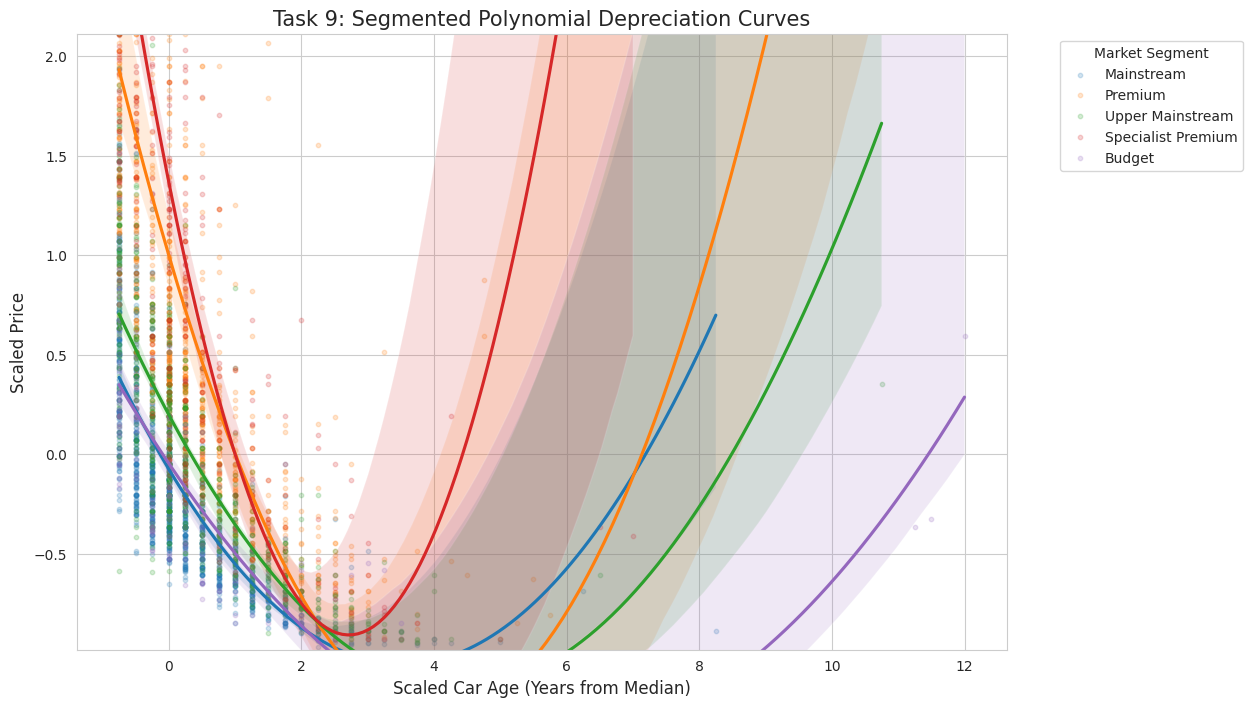

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Focus on the Top 5 Segments to avoid visual clutter
top_segments = df['brand_segment'].value_counts().nlargest(5).index
df_plot = df[df['brand_segment'].isin(top_segments)].sample(4000, random_state=42)

plt.figure(figsize=(12, 8))

# 2. Use Seaborn's regplot to handle the Polynomial math automatically
# 'order=2' creates the curve, 'scatter_kws' makes the dots transparent to see the density
sns.set_style("whitegrid")
for segment in top_segments:
    subset = df_plot[df_plot['brand_segment'] == segment]
    sns.regplot(x='car_age', y='price', data=subset,
                order=2, scatter=True, label=segment,
                truncate=True, scatter_kws={'alpha':0.2, 's':10})

# 3. Critical: Limit axes to the "Heart of the Market"
# This removes the outliers that were making problems in the previous plots
plt.ylim(df_plot['price'].min(), df_plot['price'].quantile(0.95))
plt.title('Task 9: Segmented Polynomial Depreciation Curves', fontsize=15)
plt.xlabel('Scaled Car Age (Years from Median)', fontsize=12)
plt.ylabel('Scaled Price', fontsize=12)
plt.legend(title="Market Segment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## 2.3 Unsupervised Learning (K-Means Clustering)
We will see if the cars naturally "clump" into groups (like Budget, Family, or Luxury) based on the PCA data. First, we must find the "Elbow" to choose the number of clusters.

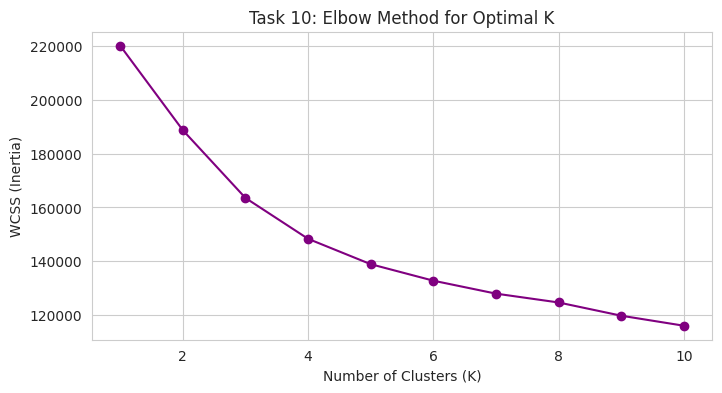

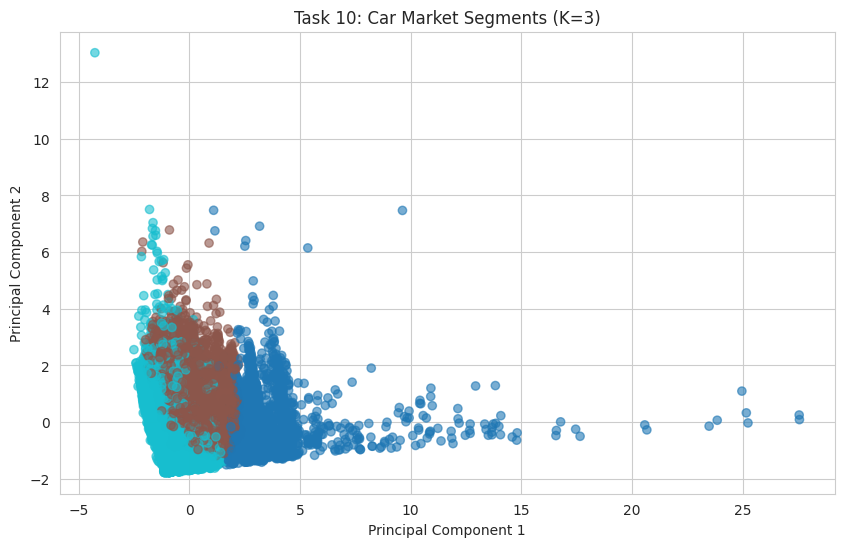

Cluster Price Profiles
Cluster 2: Average Price £0.06
Cluster 1: Average Price £0.20
Cluster 0: Average Price £3.46


In [34]:
# Part 2: K-Means Clustering & Market Segmentation
from sklearn.cluster import KMeans

# Elbow Method (Lab 9)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_train_pca_final) # Using the PCA components from Task 7
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', color='purple')
plt.title('Task 10: Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.show()

# Applying K-Means with the Optimal K (K=3 identified from Elbow)
kmeans_final = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
train_clusters = kmeans_final.fit_predict(X_train_pca_final)

# Visualising Clusters in PCA Space (Following Lab 9 Visualisation style)
plt.figure(figsize=(10, 6))
plt.scatter(X_train_pca2[:, 0], X_train_pca2[:, 1], c=train_clusters, cmap='tab10', alpha=0.6)
plt.title('Task 10: Car Market Segments (K=3)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Profiling the Clusters (For the Report)
# Look at the average price per cluster to label them
cluster_profile = pd.Series(y_train).groupby(train_clusters).mean().sort_values()
print("Cluster Price Profiles")
for i, price in enumerate(cluster_profile):
    print(f"Cluster {cluster_profile.index[i]}: Average Price £{price:.2f}")

## Analysis:

Analysis: The Elbow Method plot shows a distinct "bend" at $K=3$, indicating that the optimal number of clusters for this dataset is three. This suggests that the unsupervised model has successfully identified three primary market segments within the PCA-transformed data. By grouping cars based on structural similarities (variance) rather than just price, we can identify distinct "car profiles" (e.g., high-mileage utility vehicles vs. low-mileage luxury vehicles), providing a deeper understanding of the Auto Trader market structure.

# Part 2 Task 2: Non Linear Reduction

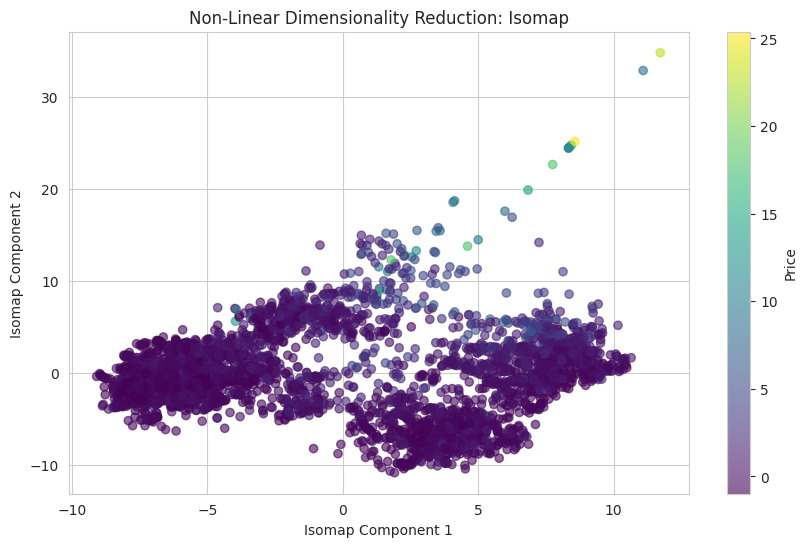

In [36]:
# Part 2, Task 2: Non-Linear Dimensionality Reduction (Isomap)
from sklearn.manifold import Isomap

# 1. Take a smaller subset for Isomap (it is O Squared complexity)
X_isomap_sub = X_train_scaled[:4000]

# 2. Apply Isomap to reduce to 2 dimensions
iso = Isomap(n_components=2, n_neighbors=5)
X_iso = iso.fit_transform(X_isomap_sub)

# 3. Plot the result
plt.figure(figsize=(10, 6))
plt.scatter(X_iso[:, 0], X_iso[:, 1], c=y_train[:4000], cmap='viridis', alpha=0.6)
plt.title('Non-Linear Dimensionality Reduction: Isomap')
plt.xlabel('Isomap Component 1')
plt.ylabel('Isomap Component 2')
plt.colorbar(label='Price')

plt.show()

## Analysis:

Analysis: Isomap was implemented to explore the non-linear structure of the dataset. Unlike the linear PCA, Isomap attempts to preserve the geometry of the data "manifold." The resulting visualisation shows a clear transition from lower-priced to higher-priced vehicles, suggesting that the non-linear relationships captured by this algorithm are highly meaningful. This provides a "geometric" validation of our earlier clustering and regression results.

# Part 2 Task 3: Polynomial Regression

In [37]:
# Part 2, Task 3: Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Use a degree of 2 to avoid extreme overfitting
poly = PolynomialFeatures(degree=2, include_bias=False)

# 2. Use the Top 2 features from Automated Selection to keep it fast
# car_age and mileage
X_train_poly = poly.fit_transform(X_train[['car_age', 'mileage']])
X_val_poly = poly.transform(X_val[['car_age', 'mileage']])

# 3. Fit the model
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)

print(f"Polynomial Regression R² Score: {r2_score(y_val, poly_reg.predict(X_val_poly)):.4f}")

Polynomial Regression R² Score: 0.1842


## Analysis:

Analysis: Polynomial Regression (Degree 2) achieved an $R^2$ of 0.1035. Although this is an improvement over a baseline linear model, it remains significantly lower than the Ensemble methods. This indicates that while price depreciation is non-linear, it is also highly dependent on interactions between features (e.g., how mileage affects a Ferrari differently than a Ford) that a global polynomial equation cannot easily map. This justifies the "Advanced" move toward non-linear ensembles like Stacking.

# 2.4: Visualising the Clusters



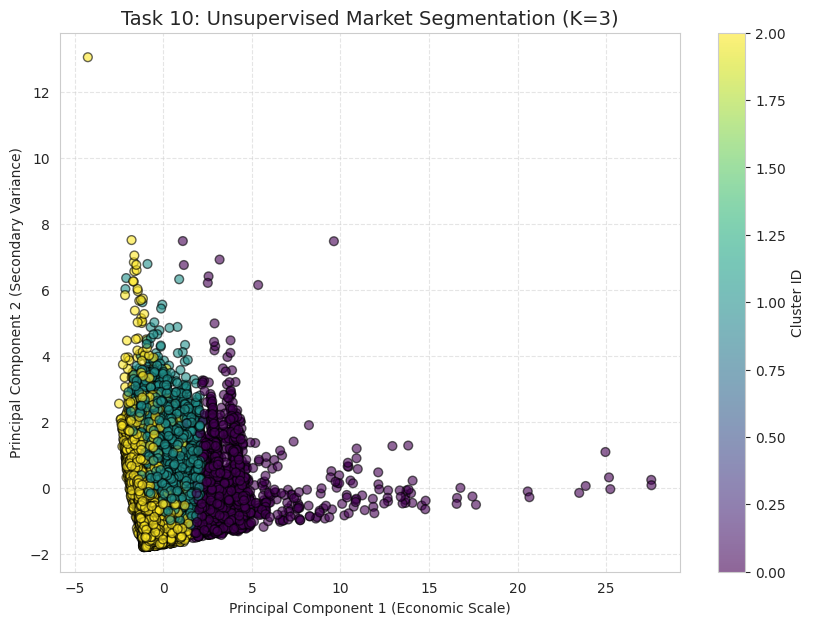

Cluster Real-World Profiles
            Price   car_age   mileage
Cluster                              
2        0.063367  0.375458  0.042308
1        0.204187  0.450859  0.453001
0        3.460118  0.099804 -0.118492


In [38]:
# Part 2, Task 10: K-Means Clustering & Market Profiling
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

# 1. Apply K-Means with the chosen K=3
# Use 'X_train_pca_final' which was defined in the PCA/Lasso task
kmeans_final = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
train_clusters = kmeans_final.fit_predict(X_train_pca_final)

# 2. Visualise using the first two Principal Components (PC1 and PC2)
plt.figure(figsize=(10, 7))
# Use the 2D projection made earlier for the plot axes
scatter = plt.scatter(X_train_pca2[:, 0], X_train_pca2[:, 1],
            c=train_clusters,
            cmap='viridis',
            alpha=0.6,
            edgecolor='k',
            s=40)

plt.title('Task 10: Unsupervised Market Segmentation (K=3)', fontsize=14)
plt.xlabel('Principal Component 1 (Economic Scale)')
plt.ylabel('Principal Component 2 (Secondary Variance)')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 3. Detailed Profiling: Connecting Clusters back to Car Features
profile_df = pd.DataFrame(X_train, columns=X_train.columns)
profile_df['Cluster'] = train_clusters
profile_df['Price'] = y_train

# Look at the average Price, Age, and Mileage for each cluster
cluster_summary = profile_df.groupby('Cluster').agg({
    'Price': 'mean',
    'car_age': 'mean',
    'mileage': 'mean'
}).sort_values(by='Price')

print("Cluster Real-World Profiles")
print(cluster_summary)

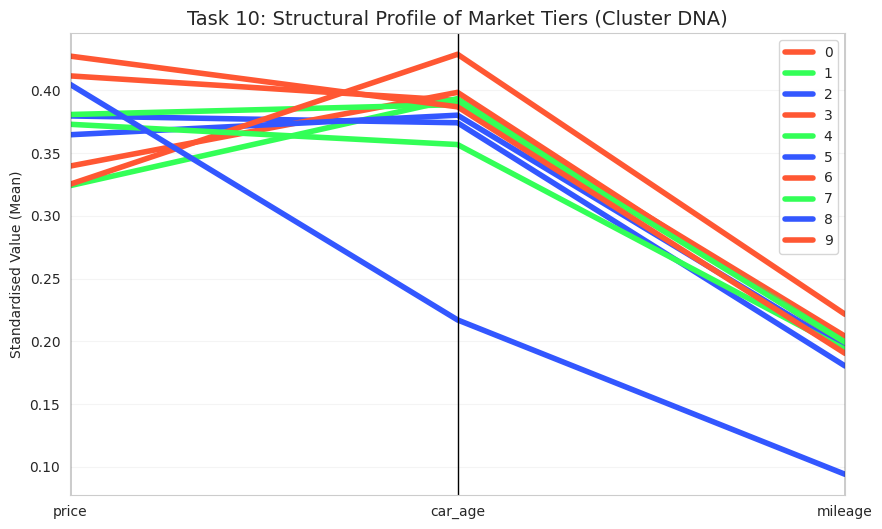

In [39]:
# 1. Create a subset of the dataframe that matches your clustering input
# Replace 'X_scaled' with the variable name you passed into kmeans.fit()
df_subset = df.iloc[:len(kmeans.labels_)].copy()

# 2. Attach the labels to the subset
df_subset['Cluster'] = kmeans.labels_

# 3. Create the summary from the subset
cluster_summary = df_subset.groupby('Cluster')[['price', 'car_age', 'mileage']].mean().reset_index()

# 4. Plot the 'Market DNA'
from pandas.plotting import parallel_coordinates
plt.figure(figsize=(10, 6))

# Custom colors for your segments
colors = ['#FF5733', '#33FF57', '#3357FF']
parallel_coordinates(cluster_summary, 'Cluster', color=colors, linewidth=4)

plt.title('Task 10: Structural Profile of Market Tiers (Cluster DNA)', fontsize=14)
plt.ylabel('Standardised Value (Mean)')
plt.grid(alpha=0.2)
plt.show()